# 5.0 Which trusts stand out from their peers?

**Board question:** which kinds of trust do better, and which trusts stand out from comparable peers?

The analysis is done in SQL. Every query lives in
[`sql/analysis/05_benchmarking.sql`](../../sql/analysis/05_benchmarking.sql) and runs against the MySQL warehouse
(`nhs_gold` views and the `nhs_silver.fct_tac` fact table). Each section below shows the query exactly as
it is in that file, then its result.

| Query | SQL technique |
| --- | --- |
| `size_quartile_kpis` | `NTILE(4)` bands labelled from their own `MIN`/`MAX` |
| `foundation_vs_nhs_trust` | Two groups pivoted side by side with conditional aggregation |
| `pay_outliers_latest_year` | `PERCENT_RANK()` cut-off and median per sector |
| `regional_health_latest_year` | Window function over an aggregate (`RANK() OVER (ORDER BY AVG(...))`) |
| `ebitda_movers` | `LAG()`, then best and worst `ROW_NUMBER()` in one pass |
| `private_patient_income_latest_year` | One SubCode from the fact table joined to the view |
| `academic_income_and_margin` | Pivoted SubCodes, `NTILE()` on a derived ratio |

**Data:** NHS England Trust Accounts Consolidation (TAC), annual and actuals only. Money is held in £000s;
columns ending `_m` or `_bn` are converted. Margins are income-weighted (`SUM / SUM`) unless a column says
otherwise. EBITDA in `v_kpis` adds back depreciation, amortisation and impairments. No query is pinned to a
year.

To run it: load the warehouse, `export DB_PASSWORD=...`, then run all cells.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Make analysis/nhs_analysis.py importable from the repo root or from this folder
here = Path.cwd()
sys.path.insert(0, str(here.parent if here.name == "notebooks" else here / "analysis"))
import nhs_analysis as nhs

nhs.set_style()
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.max_columns = 20

## 5.1 Performance by trust size

`NTILE(4)` splits trusts into four equal-sized groups by income. Each group's label comes from its own
smallest and largest income, so the bands describe the data rather than a guess at it.

In [2]:
nhs.sql("05_benchmarking", "size_quartile_kpis")

`sql/analysis/05_benchmarking.sql` → **size_quartile_kpis**

```sql
-- Trusts split into four equal-sized groups by income in the latest year, with
-- the actual income range of each group and its performance. Small trusts
-- should be compared with small trusts.
-- Technique: NTILE(4) for the bands, with the band labels built from each
-- band's own MIN and MAX rather than typed-in boundaries.
WITH banded AS (
    SELECT
        total_income_000s, operating_surplus_000s, ebitda_000s, pay_000s,
        NTILE(4) OVER (ORDER BY total_income_000s) AS size_quartile
    FROM v_kpis
    WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
)
SELECT
    size_quartile,
    CONCAT('£', ROUND(MIN(total_income_000s) / 1000), 'm to £',
           ROUND(MAX(total_income_000s) / 1000), 'm')              AS income_range,
    COUNT(*)                                                       AS trusts,
    ROUND(100 * SUM(operating_surplus_000s) / SUM(total_income_000s), 2) AS operating_margin_pct,
    ROUND(100 * SUM(ebitda_000s) / SUM(total_income_000s), 2)     AS ebitda_margin_pct,
    ROUND(100 * SUM(pay_000s) / SUM(total_income_000s), 1)        AS pay_pct_income,
    SUM(operating_surplus_000s < 0)                                AS trusts_in_deficit,
    ROUND(100 * AVG(operating_surplus_000s < 0), 1)                AS pct_in_deficit
FROM banded
GROUP BY size_quartile
ORDER BY size_quartile;
```

,size_quartile,income_range,trusts,operating_margin_pct,ebitda_margin_pct,pay_pct_income,trusts_in_deficit,pct_in_deficit
0,1,£28m to £330m,52,-2.0,3.7,69.1,34,65.4
1,2,£330m to £484m,52,-1.9,3.5,67.8,30,57.7
2,3,£485m to £763m,51,-1.3,3.7,65.7,32,62.7
3,4,£774m to £2892m,51,-0.9,3.8,61.2,28,54.9


## 5.2 Foundation trusts against NHS trusts

Both trust types are pivoted into columns with conditional aggregation, so each year is one row with the
two side by side. `AVG(IF(type, condition, NULL))` gives each group's share in deficit, because `AVG`
ignores the `NULL`s from the other group.

In [3]:
ft = nhs.sql("05_benchmarking", "foundation_vs_nhs_trust")
ft

`sql/analysis/05_benchmarking.sql` → **foundation_vs_nhs_trust**

```sql
-- Foundation trusts have more financial freedom than NHS trusts. Do they
-- perform better? Both types side by side each year, with the gap.
-- Technique: pivot the two trust types into columns with conditional
-- aggregation, so the comparison and the gap sit on one row per year.
SELECT
    financial_year,
    SUM(trust_type = 'FOUNDATION_TRUST')                                         AS foundation_trusts,
    SUM(trust_type = 'NHS_TRUST')                                                AS nhs_trusts,
    ROUND(100 * SUM(IF(trust_type = 'FOUNDATION_TRUST', ebitda_000s, 0))
              / SUM(IF(trust_type = 'FOUNDATION_TRUST', total_income_000s, 0)), 2) AS ft_ebitda_margin_pct,
    ROUND(100 * SUM(IF(trust_type = 'NHS_TRUST', ebitda_000s, 0))
              / SUM(IF(trust_type = 'NHS_TRUST', total_income_000s, 0)), 2)        AS nhs_trust_ebitda_margin_pct,
    ROUND(100 * AVG(IF(trust_type = 'FOUNDATION_TRUST', operating_surplus_000s < 0, NULL)), 1)
                                                                                  AS ft_pct_in_deficit,
    ROUND(100 * AVG(IF(trust_type = 'NHS_TRUST', operating_surplus_000s < 0, NULL)), 1)
                                                                                  AS nhs_trust_pct_in_deficit
FROM v_kpis
GROUP BY financial_year
ORDER BY financial_year;
```

,financial_year,foundation_trusts,nhs_trusts,ft_ebitda_margin_pct,nhs_trust_ebitda_margin_pct,ft_pct_in_deficit,nhs_trust_pct_in_deficit
0,2021/22,145,70,4.5,5.2,20.0,12.9
1,2022/23,144,68,4.1,4.8,45.1,32.4
2,2023/24,140,66,3.5,4.1,62.9,54.5


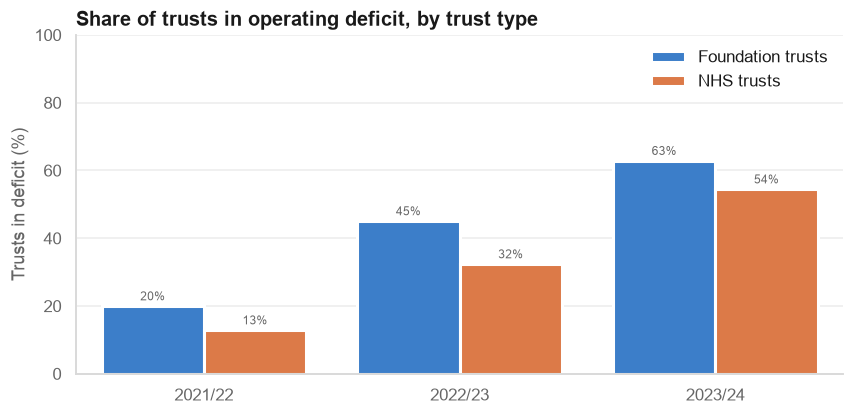

In [4]:
long = ft.melt(id_vars="financial_year", value_vars=["ft_pct_in_deficit", "nhs_trust_pct_in_deficit"],
               var_name="type", value_name="pct")
long["type"] = long["type"].map({"ft_pct_in_deficit": "Foundation trusts", "nhs_trust_pct_in_deficit": "NHS trusts"})
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=long, x="financial_year", y="pct", hue="type", ax=ax, edgecolor="white", linewidth=2,
            palette={"Foundation trusts": nhs.SECTOR_COLOURS["Acute"], "NHS trusts": nhs.SECTOR_COLOURS["Mental Health"]})
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8, padding=2, color=nhs.TEXT_SECONDARY)
ax.set(title="Share of trusts in operating deficit, by trust type", xlabel=None, ylabel="Trusts in deficit (%)", ylim=(0, 100))
ax.legend(title=None)
plt.show()

## 5.3 High pay share, judged against the trust's own sector

Pay is naturally a bigger share of income in mental health and community trusts than in acute trusts,
so a single threshold would flag the wrong trusts. `PERCENT_RANK()` within each sector keeps the top
quarter of each sector, and the distance from that sector's median ranks them.

In [5]:
nhs.sql("05_benchmarking", "pay_outliers_latest_year")

`sql/analysis/05_benchmarking.sql` → **pay_outliers_latest_year**

```sql
-- Trusts in the top quarter of their own sector for pay as a share of income
-- in the latest year, ordered by how far they sit above the sector median.
-- "High" is defined by each sector's own distribution, so a mental health trust
-- (where pay is naturally a larger share) is not judged against acute trusts.
-- Technique: PERCENT_RANK() within each sector for the cut-off, a ROW_NUMBER()
-- median per sector, both from the same CTE.
WITH latest AS (
    SELECT organisation_name, sector, region, pay_pct_income, ebitda_margin_pct
    FROM v_kpis
    WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
      AND pay_pct_income IS NOT NULL
),
ranked AS (
    SELECT
        l.*,
        PERCENT_RANK() OVER (PARTITION BY sector ORDER BY pay_pct_income) AS pct_rank,
        ROW_NUMBER()   OVER (PARTITION BY sector ORDER BY pay_pct_income) AS rn,
        COUNT(*)       OVER (PARTITION BY sector)                         AS n
    FROM latest l
),
medians AS (
    SELECT sector, AVG(CASE WHEN rn IN (FLOOR((n + 1) / 2), CEIL((n + 1) / 2)) THEN pay_pct_income END) AS median_pay_pct
    FROM ranked
    GROUP BY sector
)
SELECT
    r.sector,
    r.organisation_name,
    r.region,
    r.pay_pct_income,
    ROUND(m.median_pay_pct, 1)                       AS sector_median_pay_pct,
    ROUND(r.pay_pct_income - m.median_pay_pct, 1)    AS above_median_pts,
    ROUND(100 * r.pct_rank)                          AS percentile_in_sector,
    r.ebitda_margin_pct
FROM ranked r
JOIN medians m ON m.sector = r.sector
WHERE r.pct_rank >= 0.75
ORDER BY above_median_pts DESC
LIMIT 25;
```

,sector,organisation_name,region,pay_pct_income,sector_median_pay_pct,above_median_pts,percentile_in_sector,ebitda_margin_pct
0,Acute,Tameside and Glossop Integrated Care NHS Found...,North West,78.7,64.8,14.0,100,-3.2
1,Specialist,Liverpool Women's NHS Foundation Trust,North West,69.9,57.0,12.9,100,-9.2
2,Acute,Warrington and Halton Teaching Hospitals NHS F...,North West,77.5,64.8,12.8,99,-2.8
3,Acute,Stockport NHS Foundation Trust,North West,77.3,64.8,12.6,98,-1.4
4,Acute,Countess of Chester Hospital NHS Foundation Trust,North West,76.5,64.8,11.8,97,-5.2
5,Specialist,Sheffield Children's NHS Foundation Trust,North East and Yorkshire,67.0,57.0,10.0,93,2.8
6,Mental Health,Sheffield Health and Social Care NHS Foundatio...,North East and Yorkshire,82.2,72.8,9.4,100,-0.7
7,Acute,East Kent Hospitals University NHS Foundation ...,South East,74.1,64.8,9.4,97,-9.1
8,Acute,Barnsley Hospital NHS Foundation Trust,North East and Yorkshire,73.5,64.8,8.8,96,1.4
9,Acute,Bolton NHS Foundation Trust,North West,73.3,64.8,8.6,95,1.7


## 5.4 Regional strain

The ranking uses a window function over an aggregate: `RANK() OVER (ORDER BY AVG(...))` runs after
`GROUP BY`, so the regions are ranked on their own share of trusts in deficit in the same query.

In [6]:
nhs.sql("05_benchmarking", "regional_health_latest_year")

`sql/analysis/05_benchmarking.sql` → **regional_health_latest_year**

```sql
-- Which of the seven NHS England regions are under the most financial strain
-- in the latest year?
-- Technique: weighted margins per region, ranked with RANK() on the share of
-- trusts in deficit.
SELECT
    RANK() OVER (ORDER BY AVG(operating_surplus_000s < 0) DESC)          AS strain_rank,
    region,
    COUNT(*)                                                             AS trusts,
    ROUND(SUM(total_income_000s) / 1000, 1)                              AS income_m,
    ROUND(SUM(operating_surplus_000s) / 1000, 1)                         AS operating_surplus_m,
    ROUND(100 * SUM(operating_surplus_000s) / SUM(total_income_000s), 2) AS operating_margin_pct,
    ROUND(100 * SUM(ebitda_000s) / SUM(total_income_000s), 2)            AS ebitda_margin_pct,
    SUM(operating_surplus_000s < 0)                                      AS trusts_in_deficit,
    ROUND(100 * AVG(operating_surplus_000s < 0), 1)                      AS pct_in_deficit
FROM v_kpis
WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
  AND region IS NOT NULL
GROUP BY region
ORDER BY strain_rank;
```

,strain_rank,region,trusts,income_m,operating_surplus_m,operating_margin_pct,ebitda_margin_pct,trusts_in_deficit,pct_in_deficit
0,1,North East and Yorkshire,32,"19,349.9",-127.7,-0.7,3.5,26,81.3
1,2,North West,32,"18,152.2",-494.5,-2.7,2.7,23,71.9
2,3,South East,29,"17,824.3",-469.5,-2.6,3.2,19,65.5
3,4,Midlands,40,"22,855.2",-205.4,-0.9,3.1,23,57.5
4,5,London,32,"26,133.1",-144.8,-0.6,4.9,16,50.0
5,6,South West,19,"12,294.8",-67.2,-0.6,4.2,8,42.1
6,7,East of England,22,"12,596.5",-125.3,-1.0,4.4,9,40.9


## 5.5 Biggest movers in EBITDA margin

`LAG()` gives each trust's change since the year before; two `ROW_NUMBER()` orderings (best first and
worst first) over the same rows keep the ten most improved and ten most worsened with a single `WHERE`.

In [7]:
nhs.sql("05_benchmarking", "ebitda_movers")

`sql/analysis/05_benchmarking.sql` → **ebitda_movers**

```sql
-- The ten trusts whose EBITDA margin improved most, and the ten whose margin
-- worsened most, between the last two years.
-- Technique: LAG() for the change, then two ROW_NUMBER() orderings (best and
-- worst) over the same rows, kept with a single WHERE.
WITH changes AS (
    SELECT
        organisation_name, sector, financial_year,
        ebitda_margin_pct,
        LAG(ebitda_margin_pct) OVER (PARTITION BY org_code ORDER BY financial_year) AS prior_ebitda_margin_pct
    FROM v_kpis
),
ranked AS (
    SELECT
        c.*,
        ebitda_margin_pct - prior_ebitda_margin_pct                                             AS change_pts,
        ROW_NUMBER() OVER (ORDER BY ebitda_margin_pct - prior_ebitda_margin_pct DESC)          AS best_rank,
        ROW_NUMBER() OVER (ORDER BY ebitda_margin_pct - prior_ebitda_margin_pct ASC)           AS worst_rank
    FROM changes c
    WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
      AND prior_ebitda_margin_pct IS NOT NULL
)
SELECT
    IF(best_rank <= 10, 'Most improved', 'Most worsened')   AS movement,
    organisation_name,
    sector,
    prior_ebitda_margin_pct,
    ebitda_margin_pct,
    ROUND(change_pts, 1)                                    AS change_pts
FROM ranked
WHERE best_rank <= 10 OR worst_rank <= 10
ORDER BY change_pts DESC;
```

,movement,organisation_name,sector,prior_ebitda_margin_pct,ebitda_margin_pct,change_pts
0,Most improved,James Paget University Hospitals NHS Foundatio...,Acute,-5.4,3.4,8.8
1,Most improved,Isle of Wight NHS Trust,Acute,-4.1,4.3,8.4
2,Most improved,North Cumbria Integrated Care NHS Foundation T...,Acute,-1.0,4.4,5.4
3,Most improved,Epsom and St Helier University Hospitals NHS T...,Acute,-1.5,3.4,4.9
4,Most improved,Hampshire Hospitals NHS Foundation Trust,Acute,-1.4,3.3,4.7
5,Most improved,Dudley Integrated Health and Care NHS Trust,Mental Health,0.7,5.0,4.3
6,Most improved,Kettering General Hospital NHS Foundation Trust,Acute,-0.2,3.8,4.0
7,Most improved,Coventry and Warwickshire Partnership NHS Trust,Mental Health,-0.9,3.0,3.9
8,Most improved,Kent Community Health NHS Foundation Trust,Community,4.7,8.3,3.6
9,Most improved,Milton Keynes University Hospital NHS Foundati...,Acute,4.0,7.5,3.5


## 5.6 Private patient income

One income line (`INC0330`) is pulled from the long fact table and joined to the KPI view for context.

In [8]:
nhs.sql("05_benchmarking", "private_patient_income_latest_year")

`sql/analysis/05_benchmarking.sql` → **private_patient_income_latest_year**

```sql
-- The fifteen trusts earning most from private patients in the latest year,
-- and what share of their income it is. Private work is one lever a trust
-- can pull to improve its finances.
-- Technique: one income line (INC0330) pulled out of the long fact table and
-- joined to the KPI view, top N with RANK().
WITH private_income AS (
    SELECT org_code, total_000s AS private_000s
    FROM nhs_silver.fct_tac
    WHERE worksheet_name = 'TAC06 Op Inc 1'
      AND sub_code = 'INC0330'              -- Private patient income
      AND financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
      AND total_000s > 0
)
SELECT
    RANK() OVER (ORDER BY p.private_000s DESC)                      AS income_rank,
    k.organisation_name,
    k.sector,
    k.region,
    ROUND(p.private_000s / 1000, 1)                                 AS private_patient_income_m,
    ROUND(100 * p.private_000s / k.total_income_000s, 2)            AS pct_of_income,
    k.ebitda_margin_pct
FROM private_income p
JOIN v_kpis k
  ON k.org_code = p.org_code
 AND k.financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
ORDER BY income_rank
LIMIT 15;
```

,income_rank,organisation_name,sector,region,private_patient_income_m,pct_of_income,ebitda_margin_pct
0,1,The Royal Marsden NHS Foundation Trust,Specialist,London,181.6,28.4,6.8
1,2,Great Ormond Street Hospital for Children NHS ...,Specialist,London,78.9,11.3,6.0
2,3,Guy's & St Thomas' NHS Foundation Trust,Acute,London,73.7,2.5,4.9
3,4,Moorfields Eye Hospital NHS Foundation Trust,Specialist,London,44.1,12.9,10.3
4,5,Imperial College Healthcare NHS Trust,Acute,London,42.6,2.5,4.9
5,6,Chelsea and Westminster Hospital NHS Foundatio...,Acute,London,22.5,2.4,4.5
6,7,Royal Free London NHS Foundation Trust,Acute,London,17.9,1.2,2.9
7,8,Royal United Hospitals Bath NHS Foundation Trust,Acute,South West,16.8,3.0,4.1
8,9,Frimley Health NHS Foundation Trust,Acute,South East,15.1,1.4,2.2
9,10,University College London Hospitals NHS Founda...,Acute,London,10.1,0.6,8.6


## 5.7 Research and education income against margins

Research and development (`INC1230A`) and education and training (`INC1240A`) income are pivoted from
the fact table, turned into a share of each trust's income, and `NTILE(4)` groups trusts by that share.
The margins then show whether academic income goes with stronger finances.

In [9]:
nhs.sql("05_benchmarking", "academic_income_and_margin")

`sql/analysis/05_benchmarking.sql` → **academic_income_and_margin**

```sql
-- Does research and education income go with stronger finances? Trusts are
-- grouped into quartiles by the share of income from research and
-- development (INC1230A) and education and training (INC1240A), and each
-- group's margins are compared.
-- Technique: two SubCodes pivoted from the fact table, joined to the view,
-- NTILE(4) on the derived share, then weighted margins per quartile.
WITH academic AS (
    SELECT
        org_code,
        SUM(CASE WHEN sub_code = 'INC1230A' THEN total_000s ELSE 0 END) AS research_000s,
        SUM(CASE WHEN sub_code = 'INC1240A' THEN total_000s ELSE 0 END) AS education_000s
    FROM nhs_silver.fct_tac
    WHERE worksheet_name = 'TAC07 Op Inc 2'
      AND sub_code IN ('INC1230A', 'INC1240A')
      AND financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
    GROUP BY org_code
),
banded AS (
    SELECT
        k.total_income_000s, k.operating_surplus_000s, k.ebitda_000s,
        COALESCE(a.research_000s, 0) + COALESCE(a.education_000s, 0)                      AS academic_000s,
        NTILE(4) OVER (ORDER BY (COALESCE(a.research_000s, 0) + COALESCE(a.education_000s, 0))
                                / k.total_income_000s)                                  AS academic_quartile
    FROM v_kpis k
    LEFT JOIN academic a ON a.org_code = k.org_code
    WHERE k.financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
)
SELECT
    academic_quartile,
    COUNT(*)                                                              AS trusts,
    ROUND(100 * MIN(academic_000s / total_income_000s), 1)               AS min_academic_share_pct,
    ROUND(100 * MAX(academic_000s / total_income_000s), 1)               AS max_academic_share_pct,
    ROUND(100 * SUM(operating_surplus_000s) / SUM(total_income_000s), 2) AS operating_margin_pct,
    ROUND(100 * SUM(ebitda_000s) / SUM(total_income_000s), 2)            AS ebitda_margin_pct,
    ROUND(100 * AVG(operating_surplus_000s < 0), 1)                      AS pct_in_deficit
FROM banded
GROUP BY academic_quartile
ORDER BY academic_quartile;
```

,academic_quartile,trusts,min_academic_share_pct,max_academic_share_pct,operating_margin_pct,ebitda_margin_pct,pct_in_deficit
0,1,52,0.5,2.6,-0.9,4.2,55.8
1,2,52,2.6,3.2,-2.1,3.1,61.5
2,3,51,3.2,4.0,-1.1,3.9,66.7
3,4,51,4.0,32.6,-1.0,3.8,56.9
